In [2]:
!pip install -q kagglehub torch torchvision torchaudio
!pip install -q opencv-python pillow matplotlib scikit-learn pandas numpy
!pip install -q segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.5 MB/s eta 0:00:00


In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ashkhagan/figshare-brain-tumor-dataset")

print("Path to dataset files:", path)

100%|██████████| 839M/839M [00:09<00:00, 89.9MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ashkhagan/figshare-brain-tumor-dataset/versions/1


In [ ]:
import os

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        print(f"{indent}    {file}")

figshare-brain-tumor-dataset/
    dataset/
        README.txt
        cvind.mat
        data/
            2912.mat
            2011.mat
            3027.mat
            1912.mat
            3023.mat
            101.mat
            1194.mat
            851.mat
            2106.mat
            1850.mat


In [ ]:
import h5py
import os

mat_file = os.path.join(path, "dataset", "data", "2912.mat")

with h5py.File(mat_file, "r") as f:
    print("Keys:")
    print(list(f.keys()))

Keys:
['cjdata']


In [ ]:
with h5py.File(mat_file, "r") as f:
    cjdata = f["cjdata"]

    print("Contents of cjdata:")
    print(list(cjdata.keys()))

Contents of cjdata:
['PID', 'image', 'label', 'tumorBorder', 'tumorMask']


In [ ]:
with h5py.File(mat_file, "r") as f:
    cjdata = f["cjdata"]

    for key in cjdata.keys():
        item = cjdata[key]
        print(
            key,
            "shape =", item.shape,
            "dtype =", item.dtype
        )

PID shape = (9, 1) dtype = uint16
image shape = (512, 512) dtype = int16
label shape = (1, 1) dtype = float64
tumorBorder shape = (1, 30) dtype = float64
tumorMask shape = (512, 512) dtype = uint8


In [ ]:
import h5py
import os

mat_file = os.path.join(path, "dataset", "data", "2912.mat")

with h5py.File(mat_file, "r") as f:
    label = f["cjdata"]["label"][()]

print("Raw label:", label)

Raw label: [[2.]]


In [ ]:
import glob
import numpy as np

mat_files = glob.glob(
    os.path.join(path, "dataset", "data", "*.mat")
)

print("Number of MAT files:", len(mat_files))

labels = []

for mat_file in mat_files[:20]:
    with h5py.File(mat_file, "r") as f:
        label = f["cjdata"]["label"][()]
        labels.append(float(label[0][0]))

print("First 20 labels:")
print(labels)

Number of MAT files: 3064
First 20 labels:
[2.0, 2.0, 2.0, 2.0, 2.0, 1.0, 3.0, 2.0, 2.0, 2.0, 2.0, 3.0, 3.0, 1.0, 3.0, 1.0, 2.0, 3.0, 3.0, 2.0]


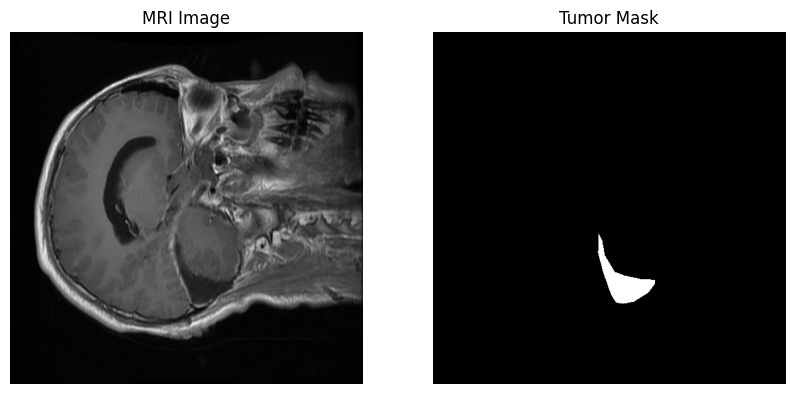

In [ ]:
import matplotlib.pyplot as plt
import h5py
import os

mat_file = os.path.join(path, "dataset", "data", "2912.mat")

with h5py.File(mat_file, "r") as f:
    cjdata = f["cjdata"]

    image = cjdata["image"][()]
    mask = cjdata["tumorMask"][()]

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("MRI Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Tumor Mask")
plt.axis("off")

plt.show()

In [ ]:
import h5py
import os
import glob
import numpy as np
from collections import Counter

mat_files = glob.glob(
    os.path.join(path, "dataset", "data", "*.mat")
)

labels = []
patient_ids = []

for mat_file in mat_files:
    with h5py.File(mat_file, "r") as f:
        cjdata = f["cjdata"]

        label = int(cjdata["label"][()][0][0])
        pid = cjdata["PID"][()].flatten()

        labels.append(label)
        patient_ids.append(tuple(pid))

print("Total images:", len(mat_files))
print("Unique patients:", len(set(patient_ids)))

print("\nClass distribution:")

class_names = {
    1: "Meningioma",
    2: "Glioma",
    3: "Pituitary"
}

counts = Counter(labels)

for label, count in sorted(counts.items()):
    print(
        f"{label} - {class_names[label]}: {count}"
    )

Total images: 3064
Unique patients: 233

Class distribution:
1 - Meningioma: 708
2 - Glioma: 1426
3 - Pituitary: 930


In [ ]:
mask_pixels = []

for mat_file in mat_files:
    with h5py.File(mat_file, "r") as f:
        mask = f["cjdata"]["tumorMask"][()]

        mask_pixels.append(np.sum(mask > 0))

print("Minimum tumor pixels:", min(mask_pixels))
print("Maximum tumor pixels:", max(mask_pixels))
print("Average tumor pixels:", np.mean(mask_pixels))

print("Images with empty masks:", sum(x == 0 for x in mask_pixels))

Minimum tumor pixels: 163
Maximum tumor pixels: 25461
Average tumor pixels: 4421.717362924282
Images with empty masks: 0


In [ ]:
import h5py
import os
import glob
import pandas as pd

mat_files = glob.glob(
    os.path.join(path, "dataset", "data", "*.mat")
)

class_names = {
    1: "Meningioma",
    2: "Glioma",
    3: "Pituitary"
}

records = []

for mat_file in mat_files:

    with h5py.File(mat_file, "r") as f:
        cjdata = f["cjdata"]

        label = int(cjdata["label"][()][0][0])
        pid = tuple(cjdata["PID"][()].flatten())

    records.append({
        "file_path": mat_file,
        "label": label,
        "class_name": class_names[label],
        "patient_id": str(pid)
    })

df = pd.DataFrame(records)

print(df.head())
print("\nTotal samples:", len(df))
print("Unique patients:", df["patient_id"].nunique())

                                           file_path  label class_name  \
0  /kaggle/input/figshare-brain-tumor-dataset/dat...      2     Glioma   
1  /kaggle/input/figshare-brain-tumor-dataset/dat...      2     Glioma   
2  /kaggle/input/figshare-brain-tumor-dataset/dat...      2     Glioma   
3  /kaggle/input/figshare-brain-tumor-dataset/dat...      2     Glioma   
4  /kaggle/input/figshare-brain-tumor-dataset/dat...      2     Glioma   

                                          patient_id  
0  (np.uint16(77), np.uint16(82), np.uint16(48), ...  
1  (np.uint16(77), np.uint16(82), np.uint16(48), ...  
2  (np.uint16(77), np.uint16(82), np.uint16(48), ...  
3  (np.uint16(77), np.uint16(82), np.uint16(48), ...  
4  (np.uint16(77), np.uint16(82), np.uint16(48), ...  

Total samples: 3064
Unique patients: 233


In [ ]:
patient_counts = df["patient_id"].value_counts()

print(patient_counts.describe())
print("\nPatients with most images:")
print(patient_counts.head(10))

count    233.000000
mean      13.150215
std        7.655779
min        1.000000
25%        7.000000
50%       13.000000
75%       18.000000
max       38.000000
Name: count, dtype: float64

Patients with most images:
patient_id
(np.uint16(77), np.uint16(82), np.uint16(48), np.uint16(51), np.uint16(50), np.uint16(51), np.uint16(50), np.uint16(50), np.uint16(67))    38
(np.uint16(77), np.uint16(82), np.uint16(48), np.uint16(53), np.uint16(49), np.uint16(54), np.uint16(52), np.uint16(52))                   37
(np.uint16(77), np.uint16(82), np.uint16(48), np.uint16(53), np.uint16(49), np.uint16(54), np.uint16(52), np.uint16(52), np.uint16(67))    35
(np.uint16(77), np.uint16(82), np.uint16(48), np.uint16(53), np.uint16(48), np.uint16(49), np.uint16(51), np.uint16(53), np.uint16(66))    34
(np.uint16(77), np.uint16(82), np.uint16(48), np.uint16(52), np.uint16(48), np.uint16(50), np.uint16(52), np.uint16(48), np.uint16(67))    31
(np.uint16(77), np.uint16(82), np.uint16(48), np.uint16(50), np

In [ ]:
import h5py
import os
import glob
import pandas as pd

mat_files = glob.glob(
    os.path.join(path, "dataset", "data", "*.mat")
)

class_names = {
    1: "Meningioma",
    2: "Glioma",
    3: "Pituitary"
}

records = []

for mat_file in mat_files:

    with h5py.File(mat_file, "r") as f:
        cjdata = f["cjdata"]

        label = int(cjdata["label"][()][0][0])

        pid_array = cjdata["PID"][()].flatten()

        # Convert character codes into a normal string
        patient_id = "".join(
            chr(int(x)) for x in pid_array
        )

    records.append({
        "file_path": mat_file,
        "label": label,
        "class_name": class_names[label],
        "patient_id": patient_id
    })

df = pd.DataFrame(records)

print(df.head())
print("\nTotal samples:", len(df))
print("Unique patients:", df["patient_id"].nunique())

                                           file_path  label class_name  \
0  /kaggle/input/figshare-brain-tumor-dataset/dat...      2     Glioma   
1  /kaggle/input/figshare-brain-tumor-dataset/dat...      2     Glioma   
2  /kaggle/input/figshare-brain-tumor-dataset/dat...      2     Glioma   
3  /kaggle/input/figshare-brain-tumor-dataset/dat...      2     Glioma   
4  /kaggle/input/figshare-brain-tumor-dataset/dat...      2     Glioma   

  patient_id  
0  MR050791B  
1   MR051586  
2   MR034997  
3  MR049104B  
4   MR034997  

Total samples: 3064
Unique patients: 233


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# First split:
# 80% train+validation
# 20% test

train_val_idx, test_idx = next(
    sgkf.split(
        df,
        y=df["label"],
        groups=df["patient_id"]
    )
)

train_val_df = df.iloc[train_val_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

print("Train + Validation:", len(train_val_df))
print("Test:", len(test_df))
print("Test patients:", test_df["patient_id"].nunique())

Train + Validation: 2419
Test: 645
Test patients: 47


In [ ]:
# Second split:
# 87.5% of train_val → training
# 12.5% → validation
#
# Overall:
# ~70% train
# ~10% validation
# ~20% test

train_val_sgkf = StratifiedGroupKFold(
    n_splits=8,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    train_val_sgkf.split(
        train_val_df,
        y=train_val_df["label"],
        groups=train_val_df["patient_id"]
    )
)

train_df = train_val_df.iloc[train_idx].reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].reset_index(drop=True)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 2099
Validation: 320
Testing: 645


In [ ]:
#Verify no patient leakage
train_patients = set(train_df["patient_id"])
val_patients = set(val_df["patient_id"])
test_patients = set(test_df["patient_id"])

print("Train ∩ Validation:", len(train_patients & val_patients))
print("Train ∩ Test:", len(train_patients & test_patients))
print("Validation ∩ Test:", len(val_patients & test_patients))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [ ]:
print("TRAIN")
print(train_df["class_name"].value_counts())

print("\nVALIDATION")
print(val_df["class_name"].value_counts())

print("\nTEST")
print(test_df["class_name"].value_counts())

TRAIN
class_name
Glioma        973
Pituitary     660
Meningioma    466
Name: count, dtype: int64

VALIDATION
class_name
Glioma        168
Meningioma     86
Pituitary      66
Name: count, dtype: int64

TEST
class_name
Glioma        285
Pituitary     204
Meningioma    156
Name: count, dtype: int64


In [ ]:
import os

os.makedirs("splits", exist_ok=True)

train_df.to_csv("splits/train.csv", index=False)
val_df.to_csv("splits/validation.csv", index=False)
test_df.to_csv("splits/test.csv", index=False)

print("Splits saved successfully!")

Splits saved successfully!


In [ ]:
from google.colab import files

files.download("splits/train.csv")
files.download("splits/validation.csv")
files.download("splits/test.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
from google.colab import files

uploaded = files.upload()

Saving test.csv to test.csv
Saving validation.csv to validation.csv
Saving train.csv to train.csv


In [5]:
import pandas as pd

train_df = pd.read_csv("train.csv")
val_df = pd.read_csv("validation.csv")
test_df = pd.read_csv("test.csv")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


Train: 2099
Validation: 320
Test: 645


In [6]:
import os
import glob

# Find all .mat files in the newly downloaded dataset
mat_files = glob.glob(
    os.path.join(path, "**", "*.mat"),
    recursive=True
)

print("MAT files found:", len(mat_files))

# Create lookup using filename
mat_lookup = {
    os.path.basename(f): f
    for f in mat_files
}

print("Example files:")
for f in list(mat_lookup.values())[:5]:
    print(f)

MAT files found: 3065
Example files:
/root/.cache/kagglehub/datasets/ashkhagan/figshare-brain-tumor-dataset/versions/1/dataset/cvind.mat
/root/.cache/kagglehub/datasets/ashkhagan/figshare-brain-tumor-dataset/versions/1/dataset/data/1460.mat
/root/.cache/kagglehub/datasets/ashkhagan/figshare-brain-tumor-dataset/versions/1/dataset/data/3033.mat
/root/.cache/kagglehub/datasets/ashkhagan/figshare-brain-tumor-dataset/versions/1/dataset/data/2043.mat
/root/.cache/kagglehub/datasets/ashkhagan/figshare-brain-tumor-dataset/versions/1/dataset/data/3026.mat


In [7]:
# Replace old paths with paths from this new Colab session

def remap_paths(df):
    df = df.copy()

    df["filename"] = df["file_path"].apply(os.path.basename)

    df["file_path"] = df["filename"].map(mat_lookup)

    return df


train_df = remap_paths(train_df)
val_df = remap_paths(val_df)
test_df = remap_paths(test_df)

print("Missing train paths:", train_df["file_path"].isna().sum())
print("Missing validation paths:", val_df["file_path"].isna().sum())
print("Missing test paths:", test_df["file_path"].isna().sum())

Missing train paths: 0
Missing validation paths: 0
Missing test paths: 0


In [8]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import h5py
import numpy as np


class BrainTumorDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        file_path = self.df.loc[idx, "file_path"]

        # Read MATLAB v7.3 file
        with h5py.File(file_path, "r") as f:
            image = f["cjdata"]["image"][()]
            label = int(f["cjdata"]["label"][()][0][0])

        # Convert image to uint8
        image = image.astype(np.float32)

        # Normalize image to 0-255
        image = (image - image.min()) / (image.max() - image.min() + 1e-8)
        image = (image * 255).astype(np.uint8)

        # Convert grayscale image to PIL
        image = Image.fromarray(image).convert("RGB")

        if self.transform:
            image = self.transform(image)

        # Convert labels:
        # 1 = Meningioma → 0
        # 2 = Glioma     → 1
        # 3 = Pituitary  → 2
        label = label - 1

        return image, label

In [9]:
#Preporcessing
from torchvision.models import ResNet18_Weights

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [10]:
train_dataset = BrainTumorDataset(
    train_df,
    transform=transform
)

val_dataset = BrainTumorDataset(
    val_df,
    transform=transform
)

test_dataset = BrainTumorDataset(
    test_df,
    transform=transform
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 2099
Validation dataset: 320
Test dataset: 645


In [11]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Label:", label)
print("Label name:", ["Meningioma", "Glioma", "Pituitary"][label])

Image shape: torch.Size([3, 224, 224])
Image dtype: torch.float32
Label: 1
Label name: Glioma


In [12]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

images, labels = next(iter(train_loader))

print("Batch images:", images.shape)
print("Batch labels:", labels.shape)
print("Labels:", labels[:10])

Batch images: torch.Size([32, 3, 224, 224])
Batch labels: torch.Size([32])
Labels: tensor([0, 1, 1, 0, 2, 0, 0, 2, 1, 2])


In [13]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [14]:
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

# Load pretrained ResNet18
model = resnet18(weights=ResNet18_Weights.DEFAULT)

# Replace final classification layer
num_features = model.fc.in_features

model.fc = nn.Linear(num_features, 3)

# Move model to GPU
model = model.to(device)

print(model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 67.8MB/s]


Linear(in_features=512, out_features=3, bias=True)


In [15]:
import numpy as np
import torch

class_counts = np.array([466, 973, 660])

class_weights = len(train_df) / (3 * class_counts)

print("Class weights:", class_weights)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

print("Loss function:", criterion)

Class weights: [1.50143062 0.71908188 1.06010101]
Loss function: CrossEntropyLoss()


In [16]:
import torch.optim as optim

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import torch


def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    all_predictions = []
    all_labels = []

    for images, labels in loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    accuracy = accuracy_score(all_labels, all_predictions)

    f1 = f1_score(
        all_labels,
        all_predictions,
        average="weighted"
    )

    return epoch_loss, accuracy, f1


def validate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    accuracy = accuracy_score(all_labels, all_predictions)

    precision = precision_score(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        average="weighted"
    )

    return epoch_loss, accuracy, precision, recall, f1

In [18]:
import os

num_epochs = 10

best_val_f1 = 0.0

os.makedirs("models", exist_ok=True)

history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": []
}


for epoch in range(num_epochs):

    train_loss, train_acc, train_f1 = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc, val_precision, val_recall, val_f1 = validate(
        model,
        val_loader,
        criterion,
        device
    )

    # Save history
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["train_f1"].append(train_f1)

    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)
    history["val_precision"].append(val_precision)
    history["val_recall"].append(val_recall)
    history["val_f1"].append(val_f1)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc:.4f} "
        f"| Train F1: {train_f1:.4f} "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc:.4f} "
        f"| Val F1: {val_f1:.4f}"
    )

    # Save best model
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1

        torch.save(
            model.state_dict(),
            "models/resnet18_brain_tumor_best.pth"
        )

        print("   ✓ Best model saved!")

Epoch [1/10] | Train Loss: 0.2629 | Train Acc: 0.9109 | Train F1: 0.9125 | Val Loss: 0.4967 | Val Acc: 0.8562 | Val F1: 0.8629
   ✓ Best model saved!
Epoch [2/10] | Train Loss: 0.0435 | Train Acc: 0.9914 | Train F1: 0.9915 | Val Loss: 0.3502 | Val Acc: 0.8719 | Val F1: 0.8749
   ✓ Best model saved!
Epoch [3/10] | Train Loss: 0.0103 | Train Acc: 0.9986 | Train F1: 0.9986 | Val Loss: 0.5278 | Val Acc: 0.8562 | Val F1: 0.8621
Epoch [4/10] | Train Loss: 0.0053 | Train Acc: 0.9995 | Train F1: 0.9995 | Val Loss: 0.4899 | Val Acc: 0.8656 | Val F1: 0.8697
Epoch [5/10] | Train Loss: 0.0021 | Train Acc: 1.0000 | Train F1: 1.0000 | Val Loss: 0.5173 | Val Acc: 0.8656 | Val F1: 0.8691
Epoch [6/10] | Train Loss: 0.0012 | Train Acc: 1.0000 | Train F1: 1.0000 | Val Loss: 0.5457 | Val Acc: 0.8688 | Val F1: 0.8707
Epoch [7/10] | Train Loss: 0.0012 | Train Acc: 1.0000 | Train F1: 1.0000 | Val Loss: 0.6157 | Val Acc: 0.8594 | Val F1: 0.8631
Epoch [8/10] | Train Loss: 0.0011 | Train Acc: 1.0000 | Train F1:

In [19]:
model.load_state_dict(
    torch.load(
        "models/resnet18_brain_tumor_best.pth",
        map_location=device
    )
)

model = model.to(device)

print("Best ResNet18 model loaded.")

Best ResNet18 model loaded.


In [20]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)
import numpy as np

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )


test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print(f"Test Accuracy: {test_accuracy:.4f}")

print("\nClassification Report:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=[
            "Meningioma",
            "Glioma",
            "Pituitary"
        ],
        digits=4
    )
)

Test Accuracy: 0.9395

Classification Report:

              precision    recall  f1-score   support

  Meningioma     0.8642    0.8974    0.8805       156
      Glioma     0.9670    0.9263    0.9462       285
   Pituitary     0.9619    0.9902    0.9758       204

    accuracy                         0.9395       645
   macro avg     0.9310    0.9380    0.9342       645
weighted avg     0.9405    0.9395    0.9397       645



In [21]:
cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[140   9   7]
 [ 20 264   1]
 [  2   0 202]]


In [22]:
from google.colab import files

files.download("models/resnet18_brain_tumor_best.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    # Moderate augmentation
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [24]:
train_dataset_aug = BrainTumorDataset(
    train_df,
    transform=train_transform
)

val_dataset_aug = BrainTumorDataset(
    val_df,
    transform=val_test_transform
)

test_dataset_aug = BrainTumorDataset(
    test_df,
    transform=val_test_transform
)

In [25]:
train_loader_aug = DataLoader(
    train_dataset_aug,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader_aug = DataLoader(
    val_dataset_aug,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader_aug = DataLoader(
    test_dataset_aug,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train:", len(train_dataset_aug))
print("Validation:", len(val_dataset_aug))
print("Test:", len(test_dataset_aug))

Train: 2099
Validation: 320
Test: 645


In [26]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

# Load pretrained ResNet18
model_improved = resnet18(
    weights=ResNet18_Weights.DEFAULT
)

# Get number of features
num_features = model_improved.fc.in_features

# Add dropout before final classification
model_improved.fc = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(num_features, 3)
)

model_improved = model_improved.to(device)

print(model_improved.fc)

Sequential(
  (0): Dropout(p=0.4, inplace=False)
  (1): Linear(in_features=512, out_features=3, bias=True)
)


In [27]:
criterion_improved = nn.CrossEntropyLoss(
    weight=class_weights
)

print(criterion_improved)

CrossEntropyLoss()


In [28]:
import torch.optim as optim

optimizer_improved = optim.AdamW(
    model_improved.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_improved,
    mode="max",
    factor=0.5,
    patience=2
)

print("Optimizer:", optimizer_improved)
print("Scheduler:", scheduler)

Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)
Scheduler: <torch.optim.lr_scheduler.ReduceLROnPlateau object at 0x7b0e4ff992b0>


In [29]:
import os
import torch

num_epochs = 15
patience = 4

best_val_f1 = 0.0
epochs_without_improvement = 0

os.makedirs("models", exist_ok=True)

history_improved = {
    "train_loss": [],
    "train_accuracy": [],
    "train_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": [],
    "learning_rate": []
}

for epoch in range(num_epochs):

    # -------------------------
    # TRAIN
    # -------------------------
    train_loss, train_acc, train_f1 = train_one_epoch(
        model_improved,
        train_loader_aug,
        criterion_improved,
        optimizer_improved,
        device
    )

    # -------------------------
    # VALIDATION
    # -------------------------
    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1
    ) = validate(
        model_improved,
        val_loader_aug,
        criterion_improved,
        device
    )

    # Current learning rate
    current_lr = optimizer_improved.param_groups[0]["lr"]

    # Save history
    history_improved["train_loss"].append(train_loss)
    history_improved["train_accuracy"].append(train_acc)
    history_improved["train_f1"].append(train_f1)

    history_improved["val_loss"].append(val_loss)
    history_improved["val_accuracy"].append(val_acc)
    history_improved["val_precision"].append(val_precision)
    history_improved["val_recall"].append(val_recall)
    history_improved["val_f1"].append(val_f1)

    history_improved["learning_rate"].append(current_lr)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc:.4f} "
        f"| Train F1: {train_f1:.4f} "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc:.4f} "
        f"| Val F1: {val_f1:.4f} "
        f"| LR: {current_lr:.6f}"
    )

    # -------------------------
    # LEARNING RATE SCHEDULER
    # -------------------------
    scheduler.step(val_f1)

    # -------------------------
    # BEST MODEL
    # -------------------------
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        epochs_without_improvement = 0

        torch.save(
            model_improved.state_dict(),
            "models/resnet18_improved_best.pth"
        )

        print("   ✓ Best improved model saved!")

    else:
        epochs_without_improvement += 1

    # -------------------------
    # EARLY STOPPING
    # -------------------------
    if epochs_without_improvement >= patience:

        print(
            f"\nEarly stopping triggered after "
            f"{epoch+1} epochs."
        )

        break

print("\nTraining finished!")
print(f"Best validation F1: {best_val_f1:.4f}")

Epoch [1/15] | Train Loss: 0.3833 | Train Acc: 0.8385 | Train F1: 0.8422 | Val Loss: 0.3912 | Val Acc: 0.8406 | Val F1: 0.8406 | LR: 0.000100
   ✓ Best improved model saved!
Epoch [2/15] | Train Loss: 0.1678 | Train Acc: 0.9438 | Train F1: 0.9444 | Val Loss: 0.3729 | Val Acc: 0.8500 | Val F1: 0.8532 | LR: 0.000100
   ✓ Best improved model saved!
Epoch [3/15] | Train Loss: 0.1061 | Train Acc: 0.9614 | Train F1: 0.9618 | Val Loss: 0.3430 | Val Acc: 0.8781 | Val F1: 0.8802 | LR: 0.000100
   ✓ Best improved model saved!
Epoch [4/15] | Train Loss: 0.0791 | Train Acc: 0.9743 | Train F1: 0.9744 | Val Loss: 0.3563 | Val Acc: 0.8594 | Val F1: 0.8644 | LR: 0.000100
Epoch [5/15] | Train Loss: 0.0623 | Train Acc: 0.9809 | Train F1: 0.9810 | Val Loss: 0.5122 | Val Acc: 0.8688 | Val F1: 0.8727 | LR: 0.000100
Epoch [6/15] | Train Loss: 0.0664 | Train Acc: 0.9771 | Train F1: 0.9772 | Val Loss: 0.3399 | Val Acc: 0.8969 | Val F1: 0.8962 | LR: 0.000100
   ✓ Best improved model saved!
Epoch [7/15] | Train

In [30]:
model_improved.load_state_dict(
    torch.load(
        "models/resnet18_improved_best.pth",
        map_location=device
    )
)

model_improved = model_improved.to(device)

print("Best improved ResNet18 loaded.")

Best improved ResNet18 loaded.


In [31]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

model_improved.eval()

all_predictions_improved = []
all_labels_improved = []

with torch.no_grad():

    for images, labels in test_loader_aug:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_improved(images)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions_improved.extend(
            predictions.cpu().numpy()
        )

        all_labels_improved.extend(
            labels.cpu().numpy()
        )


test_accuracy_improved = accuracy_score(
    all_labels_improved,
    all_predictions_improved
)

print(
    f"Improved ResNet18 Test Accuracy: "
    f"{test_accuracy_improved:.4f}"
)

print("\nClassification Report:\n")

print(
    classification_report(
        all_labels_improved,
        all_predictions_improved,
        target_names=[
            "Meningioma",
            "Glioma",
            "Pituitary"
        ],
        digits=4
    )
)

Improved ResNet18 Test Accuracy: 0.9349

Classification Report:

              precision    recall  f1-score   support

  Meningioma     0.9470    0.8013    0.8681       156
      Glioma     0.9142    0.9719    0.9422       285
   Pituitary     0.9571    0.9853    0.9710       204

    accuracy                         0.9349       645
   macro avg     0.9394    0.9195    0.9271       645
weighted avg     0.9357    0.9349    0.9334       645



In [32]:
cm_improved = confusion_matrix(
    all_labels_improved,
    all_predictions_improved
)

print("Improved ResNet18 Confusion Matrix:")
print(cm_improved)

Improved ResNet18 Confusion Matrix:
[[125  24   7]
 [  6 277   2]
 [  1   2 201]]


In [33]:
from google.colab import files

files.download("models/resnet18_improved_best.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import h5py
import cv2
import numpy as np

class BrainTumorSegmentationDataset(Dataset):

    def __init__(self, dataframe, image_size=256):
        self.df = dataframe.reset_index(drop=True)
        self.image_size = image_size

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        file_path = self.df.loc[idx, "file_path"]

        with h5py.File(file_path, "r") as f:

            image = f["cjdata"]["image"][()]
            mask = f["cjdata"]["tumorMask"][()]

        # Normalize image
        image = image.astype(np.float32)

        image = (
            image - image.min()
        ) / (
            image.max() - image.min() + 1e-8
        )

        # Resize image
        image = cv2.resize(
            image,
            (self.image_size, self.image_size),
            interpolation=cv2.INTER_AREA
        )

        # Resize mask
        mask = cv2.resize(
            mask.astype(np.uint8),
            (self.image_size, self.image_size),
            interpolation=cv2.INTER_NEAREST
        )

        # Convert image to tensor
        image = torch.from_numpy(image).float()
        image = image.unsqueeze(0)

        # Convert mask to binary
        mask = (mask > 0).astype(np.float32)

        mask = torch.from_numpy(mask).float()
        mask = mask.unsqueeze(0)

        return image, mask

In [35]:
train_seg_dataset = BrainTumorSegmentationDataset(
    train_df
)

val_seg_dataset = BrainTumorSegmentationDataset(
    val_df
)

test_seg_dataset = BrainTumorSegmentationDataset(
    test_df
)

print("Train:", len(train_seg_dataset))
print("Validation:", len(val_seg_dataset))
print("Test:", len(test_seg_dataset))

Train: 2099
Validation: 320
Test: 645


In [36]:
train_seg_loader = DataLoader(
    train_seg_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_seg_loader = DataLoader(
    val_seg_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_seg_loader = DataLoader(
    test_seg_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [37]:
image, mask = train_seg_dataset[0]

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Mask values:", torch.unique(mask))

Image shape: torch.Size([1, 256, 256])
Mask shape: torch.Size([1, 256, 256])
Mask values: tensor([0., 1.])


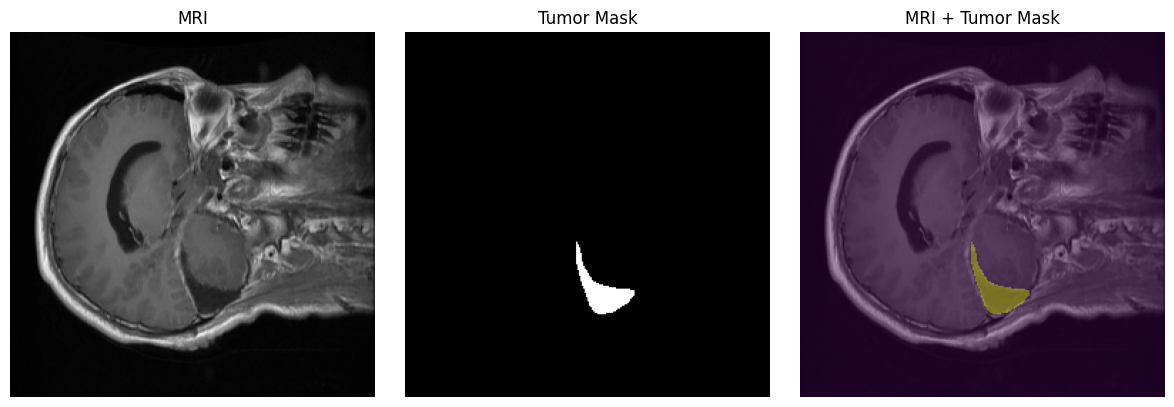

In [38]:
import matplotlib.pyplot as plt

image, mask = train_seg_dataset[0]

image = image.squeeze().numpy()
mask = mask.squeeze().numpy()

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Tumor Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image, cmap="gray")
plt.imshow(mask, alpha=0.4)
plt.title("MRI + Tumor Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [39]:
import segmentation_models_pytorch as smp

unet = smp.Unet(
    encoder_name="resnet18",
    encoder_weights="imagenet",
    in_channels=1,
    classes=1
)

unet = unet.to(device)

print(unet)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

Unet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track

In [40]:
dice_loss = smp.losses.DiceLoss(mode="binary", from_logits=True)

bce_loss = nn.BCEWithLogitsLoss()

def segmentation_loss(pred, target):
    return dice_loss(pred, target) + bce_loss(pred, target)

In [41]:
optimizer_unet = torch.optim.AdamW(
    unet.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [42]:
scheduler_unet = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_unet,
    mode="max",
    factor=0.5,
    patience=2
)

In [43]:
def dice_score(pred, target, threshold=0.5):

    pred = torch.sigmoid(pred)
    pred = (pred > threshold).float()

    intersection = (pred * target).sum(dim=(1, 2, 3))
    union = pred.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))

    dice = (2 * intersection + 1e-7) / (union + 1e-7)

    return dice.mean().item()


def iou_score(pred, target, threshold=0.5):

    pred = torch.sigmoid(pred)
    pred = (pred > threshold).float()

    intersection = (pred * target).sum(dim=(1, 2, 3))
    union = (
        pred.sum(dim=(1, 2, 3))
        + target.sum(dim=(1, 2, 3))
        - intersection
    )

    iou = (intersection + 1e-7) / (union + 1e-7)

    return iou.mean().item()

In [44]:
images, masks = next(iter(train_seg_loader))

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = unet(images)

print("Input shape :", images.shape)
print("Mask shape  :", masks.shape)
print("Output shape:", outputs.shape)

Input shape : torch.Size([16, 1, 256, 256])
Mask shape  : torch.Size([16, 1, 256, 256])
Output shape: torch.Size([16, 1, 256, 256])


In [45]:
import copy
import time

num_epochs = 15
patience = 4

best_val_dice = 0.0
epochs_without_improvement = 0

best_unet_state = None

history = {
    "train_loss": [],
    "val_loss": [],
    "train_dice": [],
    "val_dice": [],
    "val_iou": []
}

start_time = time.time()

for epoch in range(num_epochs):

    # ==========================================
    # TRAINING
    # ==========================================
    unet.train()

    train_loss = 0.0
    train_dice = 0.0
    train_batches = 0

    for images, masks in train_seg_loader:

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer_unet.zero_grad()

        outputs = unet(images)

        loss = segmentation_loss(outputs, masks)

        loss.backward()
        optimizer_unet.step()

        train_loss += loss.item()
        train_dice += dice_score(outputs.detach(), masks)

        train_batches += 1

    train_loss /= train_batches
    train_dice /= train_batches

    # ==========================================
    # VALIDATION
    # ==========================================
    unet.eval()

    val_loss = 0.0
    val_dice = 0.0
    val_iou = 0.0
    val_batches = 0

    with torch.no_grad():

        for images, masks in val_seg_loader:

            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            outputs = unet(images)

            loss = segmentation_loss(outputs, masks)

            val_loss += loss.item()
            val_dice += dice_score(outputs, masks)
            val_iou += iou_score(outputs, masks)

            val_batches += 1

    val_loss /= val_batches
    val_dice /= val_batches
    val_iou /= val_batches

    # ==========================================
    # LEARNING RATE SCHEDULER
    # ==========================================
    scheduler_unet.step(val_dice)

    current_lr = optimizer_unet.param_groups[0]["lr"]

    # ==========================================
    # SAVE HISTORY
    # ==========================================
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_dice"].append(train_dice)
    history["val_dice"].append(val_dice)
    history["val_iou"].append(val_iou)

    # ==========================================
    # PRINT RESULTS
    # ==========================================
    print(
        f"Epoch {epoch+1:02d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Dice: {train_dice:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Dice: {val_dice:.4f} | "
        f"Val IoU: {val_iou:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    # ==========================================
    # SAVE BEST MODEL
    # ==========================================
    if val_dice > best_val_dice:

        best_val_dice = val_dice
        epochs_without_improvement = 0

        best_unet_state = copy.deepcopy(unet.state_dict())

        torch.save(
            best_unet_state,
            "unet_brain_tumor_best.pth"
        )

        print(
            f"   ✓ Best U-Net saved "
            f"(Validation Dice: {best_val_dice:.4f})"
        )

    else:

        epochs_without_improvement += 1

        if epochs_without_improvement >= patience:

            print("\nEarly stopping triggered.")
            break


training_time = time.time() - start_time

print("\nTraining completed.")
print(f"Best Validation Dice: {best_val_dice:.4f}")
print(f"Training time: {training_time/60:.2f} minutes")

Epoch 01/15 | Train Loss: 1.3145 | Train Dice: 0.3342 | Val Loss: 1.1276 | Val Dice: 0.5843 | Val IoU: 0.4631 | LR: 0.000100
   ✓ Best U-Net saved (Validation Dice: 0.5843)
Epoch 02/15 | Train Loss: 1.0257 | Train Dice: 0.6430 | Val Loss: 0.9258 | Val Dice: 0.6467 | Val IoU: 0.5197 | LR: 0.000100
   ✓ Best U-Net saved (Validation Dice: 0.6467)
Epoch 03/15 | Train Loss: 0.8233 | Train Dice: 0.7163 | Val Loss: 0.7461 | Val Dice: 0.6563 | Val IoU: 0.5353 | LR: 0.000100
   ✓ Best U-Net saved (Validation Dice: 0.6563)
Epoch 04/15 | Train Loss: 0.6178 | Train Dice: 0.7612 | Val Loss: 0.6075 | Val Dice: 0.6735 | Val IoU: 0.5827 | LR: 0.000100
   ✓ Best U-Net saved (Validation Dice: 0.6735)
Epoch 05/15 | Train Loss: 0.4169 | Train Dice: 0.8046 | Val Loss: 0.4548 | Val Dice: 0.7163 | Val IoU: 0.6190 | LR: 0.000100
   ✓ Best U-Net saved (Validation Dice: 0.7163)
Epoch 06/15 | Train Loss: 0.2889 | Train Dice: 0.8298 | Val Loss: 0.3998 | Val Dice: 0.7161 | Val IoU: 0.6233 | LR: 0.000100
Epoch 07/1

In [46]:
unet.load_state_dict(
    torch.load(
        "unet_brain_tumor_best.pth",
        map_location=device
    )
)

unet = unet.to(device)
unet.eval()

print("Best U-Net loaded successfully.")

Best U-Net loaded successfully.


In [47]:
test_loss = 0.0
test_dice = 0.0
test_iou = 0.0
test_batches = 0

with torch.no_grad():

    for images, masks in test_seg_loader:

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        outputs = unet(images)

        loss = segmentation_loss(outputs, masks)

        test_loss += loss.item()
        test_dice += dice_score(outputs, masks)
        test_iou += iou_score(outputs, masks)

        test_batches += 1


test_loss /= test_batches
test_dice /= test_batches
test_iou /= test_batches

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Dice: {test_dice:.4f}")
print(f"Test IoU: {test_iou:.4f}")

Test Loss: 0.2599
Test Dice: 0.7905
Test IoU: 0.6945


In [48]:
from google.colab import files

files.download("unet_brain_tumor_best.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

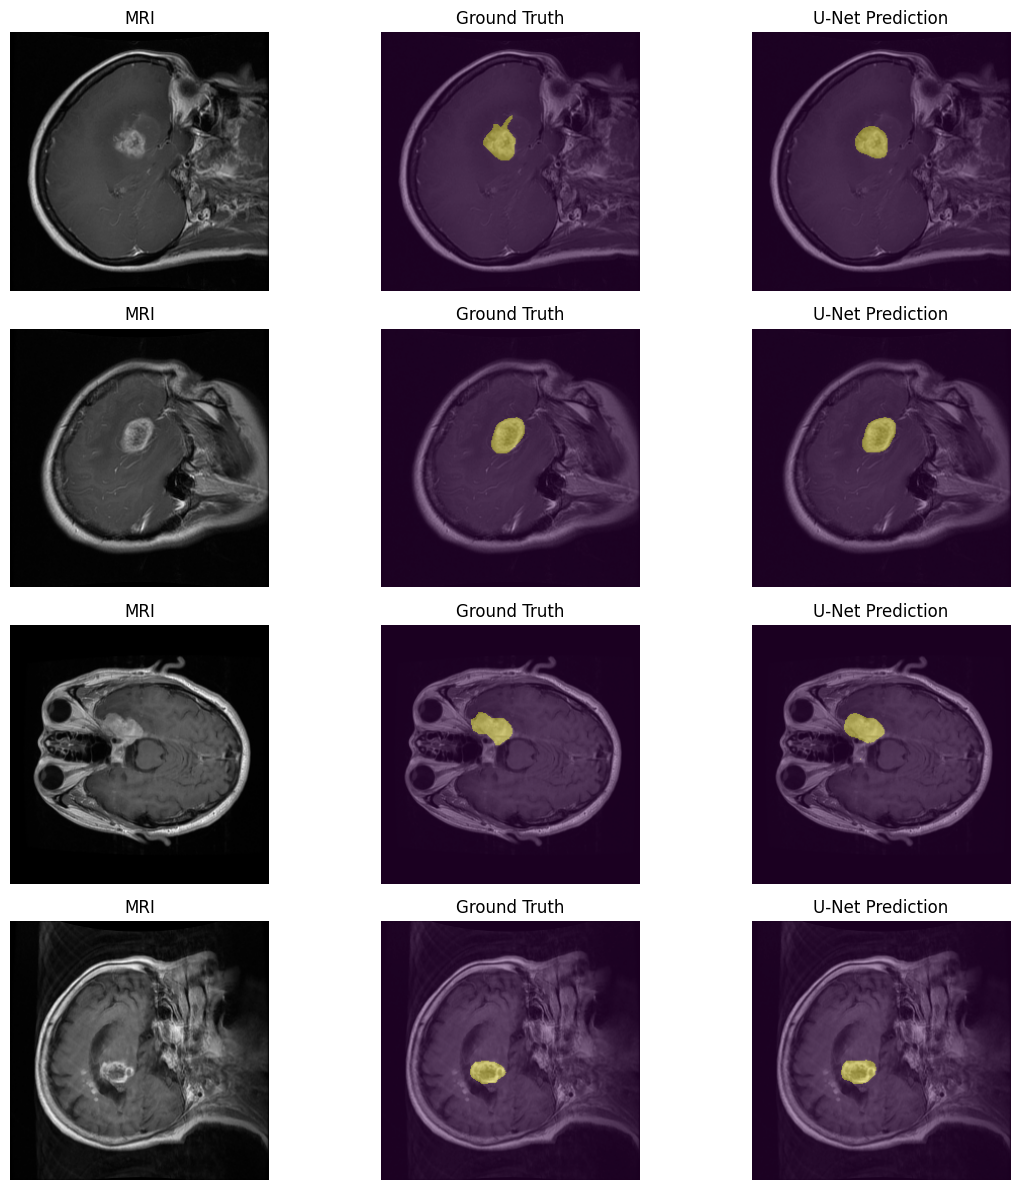

In [49]:
import matplotlib.pyplot as plt
import torch

unet.eval()

images, masks = next(iter(test_seg_loader))

images_gpu = images.to(device)

with torch.no_grad():
    outputs = unet(images_gpu)

predictions = torch.sigmoid(outputs)
predictions = (predictions > 0.5).float()

# Move first 4 samples to CPU
images = images.cpu()
masks = masks.cpu()
predictions = predictions.cpu()

plt.figure(figsize=(12, 12))

for i in range(4):

    image = images[i].squeeze().numpy()
    true_mask = masks[i].squeeze().numpy()
    pred_mask = predictions[i].squeeze().numpy()

    # MRI
    plt.subplot(4, 3, i * 3 + 1)
    plt.imshow(image, cmap="gray")
    plt.title("MRI")
    plt.axis("off")

    # Ground truth
    plt.subplot(4, 3, i * 3 + 2)
    plt.imshow(image, cmap="gray")
    plt.imshow(true_mask, alpha=0.4)
    plt.title("Ground Truth")
    plt.axis("off")

    # Prediction
    plt.subplot(4, 3, i * 3 + 3)
    plt.imshow(image, cmap="gray")
    plt.imshow(pred_mask, alpha=0.4)
    plt.title("U-Net Prediction")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [50]:
!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [51]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from torchvision.models import resnet18, ResNet18_Weights
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

In [52]:
from torchvision.models import resnet18, ResNet18_Weights

class_names = [
    "Meningioma",
    "Glioma",
    "Pituitary"
]

gradcam_model = resnet18(weights=None)

num_features = gradcam_model.fc.in_features

gradcam_model.fc = nn.Linear(
    num_features,
    3
)

gradcam_model.load_state_dict(
    torch.load(
        "models/resnet18_brain_tumor_best.pth",
        map_location=device
    )
)

gradcam_model = gradcam_model.to(device)
gradcam_model.eval()

print("ResNet18 loaded successfully.")

ResNet18 loaded successfully.


In [88]:
target_layers = [
    gradcam_model.layer4[-1]
]

In [89]:
cam = GradCAM(
    model=gradcam_model,
    target_layers=target_layers
)

print("Grad-CAM initialized successfully.")

Grad-CAM initialized successfully.


In [90]:
from PIL import Image
import cv2

gradcam_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

In [91]:
sample_index = 100
sample_path = test_df.iloc[sample_index]["file_path"]

with h5py.File(sample_path, "r") as f:
    image = f["cjdata"]["image"][()]

image = image.astype(np.float32)

image = (
    image - image.min()
) / (
    image.max() - image.min() + 1e-8
)

# Convert grayscale → RGB
image_rgb = np.stack(
    [image, image, image],
    axis=-1
)

# Convert to PIL
image_pil = Image.fromarray(
    (image_rgb * 255).astype(np.uint8)
)

input_tensor = gradcam_transform(
    image_pil
).unsqueeze(0).to(device)

print("Input:", input_tensor.shape)

Input: torch.Size([1, 3, 224, 224])


In [92]:
with torch.no_grad():

    output = gradcam_model(input_tensor)

    probabilities = torch.softmax(
        output,
        dim=1
    )

    predicted_class = probabilities.argmax(
        dim=1
    ).item()

    confidence = probabilities[0, predicted_class].item()

print("Predicted class:", class_names[predicted_class])
print("Confidence:", f"{confidence * 100:.2f}%")

Predicted class: Pituitary
Confidence: 100.00%


In [93]:
targets = [
    ClassifierOutputTarget(predicted_class)
]

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)

grayscale_cam = grayscale_cam[0]

print("Grad-CAM shape:", grayscale_cam.shape)

Grad-CAM shape: (224, 224)


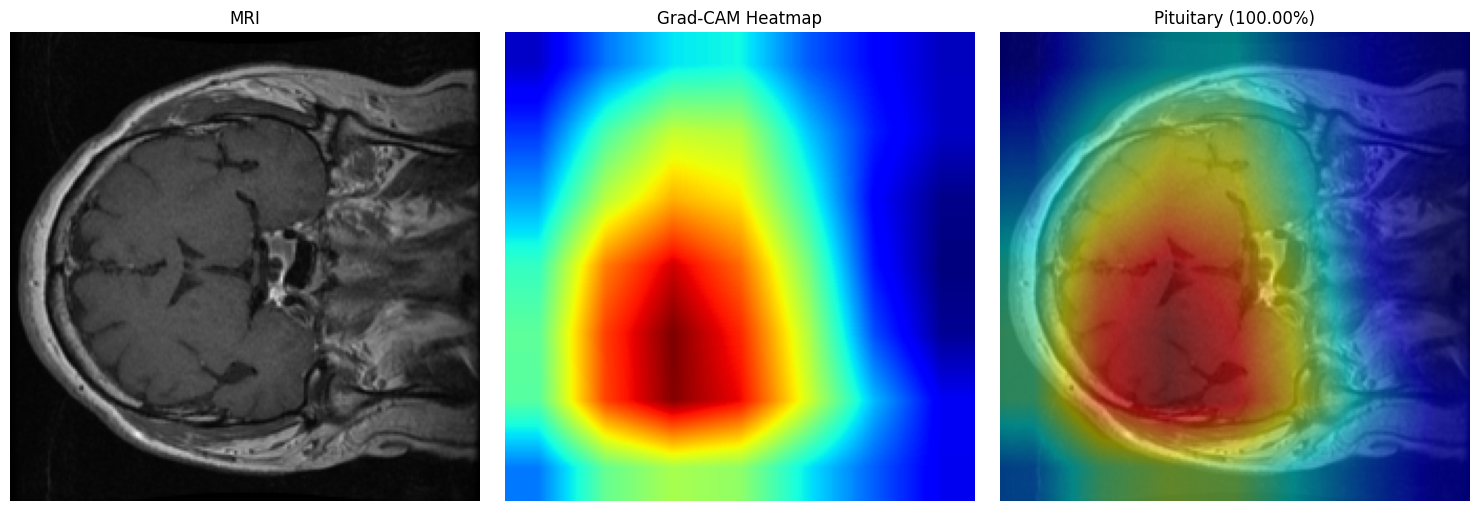

In [94]:
# Resize the original RGB image to match Grad-CAM size
rgb_image = cv2.resize(
    image_rgb,
    (224, 224),
    interpolation=cv2.INTER_AREA
).astype(np.float32)

# Make sure values are between 0 and 1
rgb_image = np.clip(rgb_image, 0, 1)

visualization = show_cam_on_image(
    rgb_image,
    grayscale_cam,
    use_rgb=True
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb_image)
plt.title("MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(grayscale_cam, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(visualization)
plt.title(
    f"{class_names[predicted_class]} "
    f"({confidence*100:.2f}%)"
)
plt.axis("off")

plt.tight_layout()
plt.show()